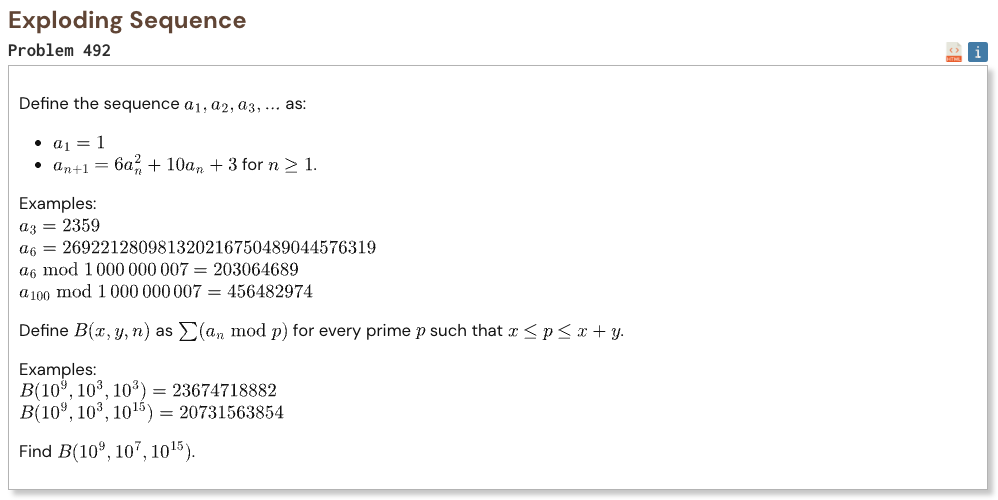

## Initial approach

- transform the original recurrence into a much simpler repeated squaring sequence
- connect this new sequence to a Lucas sequence
- reduce the enormous index separately for each prime
- use fast doubling to calculate the needed Lucas value modulo that prime
- generate all primes in the required interval with a segmented sieve
- convert each Lucas value back to the original sequence and add the remainders

In [1]:
%%time

from math import isqrt

X = 10**9
Y = 10**7
N = 10**15

def primes_up_to(limit):
    sieve = bytearray(b"\x01") * (limit + 1)
    sieve[0:2] = b"\x00\x00"

    for p in range(2, isqrt(limit) + 1):
        if sieve[p]:
            start = p * p
            sieve[start:limit + 1:p] = b"\x00" * (
                (limit - start) // p + 1
            )

    return [p for p in range(2, limit + 1) if sieve[p]]

def primes_in_range(low, high):
    segment = bytearray(b"\x01") * (high - low + 1)

    for p in primes_up_to(isqrt(high)):
        start = max(p * p, ((low + p - 1) // p) * p)

        segment[start - low:high - low + 1:p] = b"\x00" * (
            (high - start) // p + 1
        )

    return [
        low + i
        for i, value in enumerate(segment)
        if value and low + i >= 2
    ]

def lucas_v(index, mod):
    v0 = 2
    v1 = 11

    for bit in bin(index)[2:]:
        v2m = (v0 * v0 - 2) % mod
        v2m1 = (v0 * v1 - 11) % mod
        v2m2 = (v1 * v1 - 2) % mod

        if bit == "0":
            v0, v1 = v2m, v2m1
        else:
            v0, v1 = v2m1, v2m2

    return v0

result = 0

for p in primes_in_range(X, X + Y):
    legendre = pow(117, (p - 1) // 2, p)

    if legendre == 1:
        period = p - 1
    else:
        period = p + 1

    index = pow(2, N - 1, period)
    b = lucas_v(index, p)
    a = (b - 5) * pow(6, p - 2, p) % p

    result += a

print("Result:", result)

Result: 242586962923928
CPU times: user 4.42 s, sys: 37.7 ms, total: 4.46 s
Wall time: 4.48 s
